### Ego + exo fusion, and V-JEPA 2 vs TimeSformer, with event-weighted pooling

The best single-source result so far (`goodtip_aspects.ipynb`): frozen TimeSformer-base K600 on the best exo camera at
8 FPS, patch-token std at layer 12, averaged over the 25% of 7 s windows an event detector (trained on where experts
paused to comment) scores highest: within-scenario Spearman 0.476. Two questions:

1. **Encoder.** Does frozen **V-JEPA 2 ViT-L** (`facebook/vjepa2-vitl-fpc64-256`; self-supervised by predicting masked
   video, not trained to classify actions) beat TimeSformer on the same views? 2 s clips of 16 frames at 8 FPS, the whole
   frame resized to 256x256; per clip the mean and std over its 2048 tokens at layers 12 and 24. Each 2 s clip is
   repeated over its two seconds, so both encoders share the 1 s window grid.
2. **Fusion.** Ego and exo videos are frame-aligned, so every window exists in both views. Three ways to fuse:
   * **concat**: each view's pooled token std reduced to PCA-64 (inside the fold), concatenated, one probe. Windows chosen
     by each view's own detector ("own events") or by one detector on both views ("fused events").
   * **per-scenario stacking**: one probe per view; inside each training fold, out-of-fold predictions of an inner 5-fold
     CV (by participant) pick, per scenario, the weight of each view (grid on the simplex), separately for the ridge
     (max within-scenario Spearman) and the logistic probe (min log loss). View effects were scenario-specific and
     opposite with Qwen features (exo helped Rock Climbing, hurt Dance), which one shared probe can't express.

Protocol as before: all 1,338 takes, 4 x 5-fold CV split by participant, scenario-centered blocks, PCA-64 inside the
fold, scenario one-hot; accuracy (logistic) and within-scenario Spearman (ridge, predictions centered within fold and
scenario); 95% participant bootstrap. Event detectors are refit in every fold on the fitting participants only. In the
stacking, the inner out-of-fold predictions use features pooled with the outer fold's detector (fit on all fitting
participants), which only affects the choice of weights. "Best single view" in the comparisons is picked by its point
estimate, which favours the single views.

**Gates**: V-JEPA 2 vs TimeSformer on the same view and pooling, and fusion vs the best single view of the same
encoder: paired bootstrap interval of the Spearman difference above 0.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video


train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


#### 1. Features on a shared 1 s window grid

Per source and second: TimeSformer L12 [CLS, patch mean, patch std] (2304) or V-JEPA 2 [token mean, token std] (2048).
Window j = mean of seconds j - 5 .. j + 1 (6 s before to 1 s after, clamped), as in `goodtip_aspects.ipynb`. The
detector sees windows minus the take's mean second; pooling uses only the token-std part.

In [2]:
import gc

import torch
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

EMBEDDING_DIR = Path("embeddings")
all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([clip_of[t]["seconds"] for t in names])
WINDOW = 7

def windows_of(x):
    """(n seconds, D) -> (n, D): window j = mean of seconds j - WINDOW + 2 .. j + 1, clamped to the take."""
    c = np.vstack([np.zeros((1, x.shape[1])), np.cumsum(x, 0, dtype=np.float64)])
    j = np.arange(len(x))
    lo, hi = np.maximum(0, j - WINDOW + 2), np.minimum(len(x), j + 2)
    return ((c[hi] - c[lo]) / (hi - lo)[:, None]).astype(np.float32)

def fit_length(x, n):
    """Trim to n rows, or repeat the last row up to n."""
    return x[:n] if len(x) >= n else np.vstack([x, np.repeat(x[-1:], n - len(x), 0)])

centered_windows, std_windows, uniform_pool, SOURCE_INFO = {}, {}, {}, {}

def add_source(name, per_second, std_part, for_detector=True):
    cw, sw = {}, {}
    for t in names:
        x = per_second(t)
        w = windows_of(x)
        if for_detector:
            cw[t] = (w - x.mean(0)).astype(np.float16)
        sw[t] = w[:, std_part].astype(np.float16)
    if for_detector:
        centered_windows[name] = cw
    std_windows[name] = sw
    uniform_pool[name] = np.stack([sw[t].astype(np.float32).mean(0) for t in names])

# Reference grid: TimeSformer exo clips (1 s each).
ts_exo = torch.load(EMBEDDING_DIR / "timesformer_k600_exo8fps_clips.pt", mmap=True)
n_seconds = {t: len(ts_exo["clips"]["squash"][t]) for t in names}
add_source("TS exo", lambda t: ts_exo["clips"]["squash"][t][:, 1].float().reshape(n_seconds[t], -1).numpy(), slice(1536, 2304))
del ts_exo
SOURCE_INFO["TS exo"] = "TimeSformer K600, best exo, L12"

path = EMBEDDING_DIR / "timesformer_k600_ego8fps_clips.pt"
if path.exists():
    ts_ego = torch.load(path, mmap=True)
    mismatched = sum(len(ts_ego["clips"]["squash"][t]) != n_seconds[t] for t in names)
    print(f"TimeSformer ego: {mismatched} takes whose clip count differs from exo (trimmed / padded)")
    add_source("TS ego", lambda t: fit_length(ts_ego["clips"]["squash"][t][:, 1].float().reshape(-1, 2304).numpy(), n_seconds[t]),
               slice(1536, 2304))
    SOURCE_INFO["TS ego"] = "TimeSformer K600, ego, L12"
    del ts_ego

for view in ("exo", "ego"):
    path = EMBEDDING_DIR / f"vjepa2_vitl_{view}8fps_clips.pt"
    if not path.exists():
        continue
    vj = torch.load(path, mmap=True)
    missing = [t for t in names if t not in vj["clips"]]
    if missing:
        print(f"V-JEPA {view}: cache incomplete ({len(missing)} takes missing), skipped")
        del vj
        continue
    def per_second(t, li):
        x = vj["clips"][t][:, li].float().reshape(len(vj["clips"][t]), -1).numpy()  # (2 s clips, 2048)
        return x[np.minimum(np.arange(n_seconds[t]) // 2, len(x) - 1)]
    add_source(f"VJ {view}", lambda t: per_second(t, 1), slice(1024, 2048))
    add_source(f"VJ {view} L12", lambda t: per_second(t, 0), slice(1024, 2048), for_detector=False)
    SOURCE_INFO[f"VJ {view}"] = f"V-JEPA 2 ViT-L, {view}, L24"
    SOURCE_INFO[f"VJ {view} L12"] = f"V-JEPA 2 ViT-L, {view}, L12"
    del vj
gc.collect()
SOURCES = list(std_windows)
OWN_DETECTOR = {s: s.replace(" L12", "") for s in SOURCES}
n_windows = n_seconds
print(f"{sum(n_windows.values())} windows over {len(names)} takes; sources: " +
      "; ".join(f"{s} ({SOURCE_INFO[s]})" for s in SOURCES))

TimeSformer ego: 0 takes whose clip count differs from exo (trimmed / padded)


147085 windows over 1338 takes; sources: TS exo (TimeSformer K600, best exo, L12); TS ego (TimeSformer K600, ego, L12); VJ exo (V-JEPA 2 ViT-L, exo, L24); VJ exo L12 (V-JEPA 2 ViT-L, exo, L12); VJ ego (V-JEPA 2 ViT-L, ego, L24); VJ ego L12 (V-JEPA 2 ViT-L, ego, L12)


#### 2. Events and event detectors

Events as in `goodtip_aspects.ipynb`: all experts' pauses of a take grouped greedily (a new event starts more than
4 s after the current event's first pause). Positives: the window at each event's last pause; negatives: windows more
than 7 s from every pause, as many as the take's events. One detector per view and encoder, and one per encoder on both
views (PCA-64 of each view, concatenated). AUC on held-out participants (5 folds).

In [3]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

EVENT_GAP = 4.0
mom = pd.DataFrame(moments)
mom["pause"] = mom.take_name + "|" + mom.expert + "|" + mom.time.round(2).astype(str)
pauses = mom.groupby("pause").agg(take_name=("take_name", "first"), time=("time", "first")).reset_index()
event_of = {}
for take, group in pauses.sort_values("time").groupby("take_name"):
    start, k = None, -1
    for pause, time in zip(group.pause, group.time):
        if start is None or time - start > EVENT_GAP:
            start, k = time, k + 1
        event_of[pause] = f"{take}#{k}"
pauses["event"] = pauses.pause.map(event_of)
events = pauses.groupby("event").agg(take_name=("take_name", "first"), end=("time", "max")).reset_index()
events["participant"] = events.take_name.map(lambda t: clip_of[t]["participant"])
events["scenario"] = events.take_name.map(lambda t: clip_of[t]["scenario"])
pause_times = pauses.groupby("take_name").time.apply(lambda s: np.unique(s.to_numpy()))

rng = np.random.default_rng(0)
detect = []
for take, group in events.groupby("take_name"):
    js = sorted({min(int(e), n_windows[take] - 1) for e in group.end})
    detect += [(take, j, 1) for j in js]
    far = np.array([np.abs(j - pause_times[take]).min() > WINDOW for j in range(n_windows[take])])
    candidates = np.flatnonzero(far)
    for j in rng.choice(candidates, min(len(js), len(candidates)), replace=False):
        detect.append((take, int(j), 0))
detect = pd.DataFrame(detect, columns=["take_name", "j", "event"])
detect["participant"] = detect.take_name.map(lambda t: clip_of[t]["participant"])
detect["scenario"] = detect.take_name.map(lambda t: clip_of[t]["scenario"])
y_det = detect.event.to_numpy()
print(f"{len(events)} events in {events.take_name.nunique()} takes; {len(detect)} detection windows ({y_det.sum()} events)")

DETECTORS = {s: [s] for s in centered_windows}
for enc in ("TS", "VJ"):
    if f"{enc} ego" in centered_windows and f"{enc} exo" in centered_windows:
        DETECTORS[f"{enc} ego+exo"] = [f"{enc} ego", f"{enc} exo"]
X_det = {d: np.hstack([np.stack([centered_windows[s][t][j] for t, j in zip(detect.take_name, detect.j)]).astype(np.float32)
                       for s in parts]) for d, parts in DETECTORS.items()}

def detector(d):
    """Per view: standardize -> PCA-64; views concatenated -> standardize -> logistic."""
    dims = [centered_windows[s][names[0]].shape[1] for s in DETECTORS[d]]
    edges = np.concatenate([[0], np.cumsum(dims)])
    blocks = ColumnTransformer([(f"v{i}", make_pipeline(StandardScaler(), PCA(64, svd_solver="randomized", random_state=0)),
                                 slice(int(a), int(b))) for i, (a, b) in enumerate(zip(edges[:-1], edges[1:]))])
    return make_pipeline(blocks, StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 1, 6), cv=3, max_iter=3000, n_jobs=-1))

def event_scores(model, d):
    return {t: model.decision_function(np.hstack([centered_windows[s][t] for s in DETECTORS[d]]).astype(np.float32))
            for t in names}

detection_scores = {d: np.zeros(len(detect)) for d in DETECTORS}
for fit, held in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(detect, y_det, detect.participant):
    for d in DETECTORS:
        detection_scores[d][held] = detector(d).fit(X_det[d][fit], y_det[fit]).decision_function(X_det[d][held])
det_scen = sorted(detect.scenario.unique())
print(f"{'detection AUC':<16}" + "".join(f"{s[:11]:>13}" for s in ["all", *det_scen]))
for d, s in detection_scores.items():
    print(f"{d:<16}{roc_auc_score(y_det, s):>13.3f}" + "".join(
        f"{roc_auc_score(y_det[m], s[m]):>13.3f}" for m in [(detect.scenario == sc).to_numpy() for sc in det_scen]))

6646 events in 432 takes; 11620 detection windows (6630 events)


detection AUC             all   Basketball      Cooking        Dance        Music       Soccer
TS exo                  0.722        0.862        0.711        0.897        0.634        0.832
TS ego                  0.731        0.894        0.745        0.771        0.660        0.697
VJ exo                  0.743        0.891        0.717        0.908        0.700        0.854
VJ ego                  0.729        0.876        0.745        0.829        0.660        0.680
TS ego+exo              0.755        0.909        0.747        0.889        0.670        0.884
VJ ego+exo              0.753        0.939        0.739        0.906        0.688        0.866


#### 3. Proficiency probes: single views, concat fusion, per-scenario stacking

In [4]:
from itertools import product

N_REPEATS, N_FOLDS, PCA_DIMS, TOP, INNER_FOLDS = 4, 5, 64, 0.25, 5
LEVEL_VALUES = np.array([1, 2, 3, 4])

REPS = {}
for s in SOURCES:
    REPS[f"{s}: uniform"] = [(s, None)]
    REPS[f"{s}: top 25%"] = [(s, OWN_DETECTOR[s])]
for enc in ("TS", "VJ"):
    ego, exo = f"{enc} ego", f"{enc} exo"
    if ego in SOURCES and exo in SOURCES:
        REPS[f"{enc} ego+exo: concat, uniform"] = [(ego, None), (exo, None)]
        REPS[f"{enc} ego+exo: concat, own events"] = [(ego, ego), (exo, exo)]
        REPS[f"{enc} ego+exo: concat, fused events"] = [(ego, f"{enc} ego+exo"), (exo, f"{enc} ego+exo")]
for view in ("exo", "ego"):
    if f"TS {view}" in SOURCES and f"VJ {view}" in SOURCES:
        REPS[f"TS + VJ {view}: concat"] = [(f"TS {view}", f"TS {view}"), (f"VJ {view}", f"VJ {view}")]
FOUR = ["TS ego", "TS exo", "VJ ego", "VJ exo"]
if all(s in SOURCES for s in FOUR):
    REPS["all four: concat, own events"] = [(s, s) for s in FOUR]
STACKS = {}
for enc in ("TS", "VJ"):
    if f"{enc} ego" in SOURCES and f"{enc} exo" in SOURCES:
        STACKS[f"{enc} ego+exo: per-scenario stacking"] = [f"{enc} ego: top 25%", f"{enc} exo: top 25%"]
if all(s in SOURCES for s in FOUR):
    STACKS["all four: per-scenario stacking"] = [f"{s}: top 25%" for s in FOUR]

def simplex(k, step):
    n = int(round(1 / step))
    return np.array([c for c in product(range(n + 1), repeat=k) if sum(c) == n], float) / n
GRIDS = {k: simplex(k, 0.1 if k == 2 else 0.25) for k in (2, 4)}

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def log_loss_rows(p, y):
    return -np.log(np.clip(p[np.arange(len(y)), y - 1], 1e-9, None)).mean()

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
fold_of = np.zeros((N_REPEATS, len(names)), int)
stack_weights = []
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        d_fit = detect.participant.isin(set(participants[fit])).to_numpy()
        det_scores = {d: event_scores(detector(d).fit(X_det[d][d_fit], y_det[d_fit]), d) for d in DETECTORS}
        pool_cache = {}
        def pooled(src, sel):
            if sel is None:
                return uniform_pool[src]
            if (src, sel) not in pool_cache:
                out = []
                for t in names:
                    w, s = std_windows[src][t], det_scores[sel][t]
                    out.append(w[np.argsort(-s)[:max(1, int(round(TOP * len(w))))]].astype(np.float32).mean(0))
                pool_cache[src, sel] = np.stack(out)
            return pool_cache[src, sel]
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def fit_predict(blocks, fit_idx, pred_idx):
            """blocks: list of (n_takes, d) arrays -> (probabilities (n_pred, 4), ridge prediction (n_pred,))."""
            parts = [onehot]
            for X in blocks:
                Xc = centered(X, scenarios, fit_idx)
                parts.append(PCA(PCA_DIMS, svd_solver="full").fit(Xc[fit_idx]).transform(Xc) if X.shape[1] > PCA_DIMS else Xc)
            X = np.hstack(parts)
            probe = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
            probe.fit(X[fit_idx], scores[fit_idx])
            p = np.zeros((len(pred_idx), 4))
            p[:, probe.classes_ - 1] = probe.predict_proba(X[pred_idx])
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit_idx], scores[fit_idx])
            return p, ridge.predict(X[pred_idx])

        def record(key, p, c):
            hits[key][repeat, held] = LEVEL_VALUES[p.argmax(1)] == scores[held]
            continuous[key][repeat, held] = c

        record("scenario only", *fit_predict([], fit, held))
        duration = centered(log_duration[:, None], scenarios, fit)
        record("duration only", *fit_predict([np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES])], fit, held))
        outer = {}
        for key, parts in REPS.items():
            outer[key] = fit_predict([pooled(src, sel) for src, sel in parts], fit, held)
            record(key, *outer[key])

        # Per-scenario stacking: inner out-of-fold predictions on the fitting takes choose each scenario's view weights.
        inner_oof = {}
        inner_folds = list(StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=100 + repeat).split(fit, scores[fit], participants[fit]))
        for base in sorted({b for bases in STACKS.values() for b in bases}):
            p_oof, c_oof = np.zeros((len(fit), 4)), np.zeros(len(fit))
            for ifit, iheld in inner_folds:
                p_oof[iheld], c_oof[iheld] = fit_predict([pooled(src, sel) for src, sel in REPS[base]], fit[ifit], fit[iheld])
            inner_oof[base] = p_oof, c_oof
        for key, bases in STACKS.items():
            grid = GRIDS[len(bases)]
            P_fit = np.stack([inner_oof[b][0] for b in bases])  # (k, n_fit, 4)
            C_fit = np.stack([inner_oof[b][1] for b in bases])
            P_held = np.stack([outer[b][0] for b in bases])
            C_held = np.stack([outer[b][1] for b in bases])
            p_out, c_out = np.zeros((len(held), 4)), np.zeros(len(held))
            for s in SCENARIO_NAMES:
                f_rows, h_rows = scenarios[fit] == s, scenarios[held] == s
                y = scores[fit][f_rows]
                rho = [spearmanr(w @ C_fit[:, f_rows], y)[0] for w in grid]
                w_c = grid[int(np.nanargmax(np.nan_to_num(rho, nan=-2)))]
                w_p = grid[int(np.argmin([log_loss_rows(np.tensordot(w, P_fit[:, f_rows], 1), y) for w in grid]))]
                p_out[h_rows] = np.tensordot(w_p, P_held[:, h_rows], 1)
                c_out[h_rows] = w_c @ C_held[:, h_rows]
                stack_weights.append({"stack": key, "repeat": repeat, "fold": fold, "scenario": s,
                                      **{f"ridge {b}": w for b, w in zip(bases, w_c)}, **{f"probe {b}": w for b, w in zip(bases, w_p)}})
            record(key, p_out, c_out)
        print(f"repeat {repeat + 1} fold {fold + 1} done", flush=True)
stack_weights = pd.DataFrame(stack_weights)
print(f"{len(hits)} representations x {N_REPEATS} repeats x {len(names)} takes")

repeat 1 fold 1 done


repeat 1 fold 2 done


repeat 1 fold 3 done


repeat 1 fold 4 done


repeat 1 fold 5 done


repeat 2 fold 1 done


... (11 outputs left out)

repeat 4 fold 3 done


repeat 4 fold 4 done


repeat 4 fold 5 done


26 representations x 4 repeats x 1338 takes


#### 4. Results with participant-bootstrap intervals, and the gates

In [5]:
N_BOOTSTRAP = 500
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]
level_centered = scores.astype(float).copy()
for s in SCENARIO_NAMES:
    level_centered[scenarios == s] -= scores[scenarios == s].mean()

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}
per_take = {key: h.mean(0) for key, h in hits.items()}
def rho(key, rows_):
    a = ordinal[key][rows_]
    return spearmanr(a, level_centered[rows_])[0] if np.std(a) > 1e-9 else 0.0
ALL = np.arange(len(names))
boot_rho = {key: np.array([rho(key, r) for r in resamples]) for key in ordinal}
boot_acc = {key: np.array([per_take[key][r].mean() for r in resamples]) for key in per_take}
summary = {key: (rho(key, ALL), *np.quantile(boot_rho[key], [0.025, 0.975]), per_take[key].mean(),
                 *np.quantile(boot_acc[key], [0.025, 0.975])) for key in ordinal}

ORDER = ["scenario only", "duration only", *REPS, *STACKS]
print(f"{'representation':<44}{'Spearman with level':>27}{'accuracy':>25}")
for key in ORDER:
    s = summary[key]
    print(f"{key:<44}{s[0]:>+9.3f} [{s[1]:+.3f}, {s[2]:+.3f}]{s[3]:>9.3f} [{s[4]:.3f}, {s[5]:.3f}]")

def diff(a, b):
    d = boot_rho[a] - boot_rho[b]
    return summary[a][0] - summary[b][0], *np.quantile(d, [0.025, 0.975])

def best_single(enc):
    keys = [f"{enc} {v}: top 25%" for v in ("ego", "exo") if f"{enc} {v}: top 25%" in summary]
    return max(keys, key=lambda k: summary[k][0]) if keys else None

COMPARISONS = []
for s in SOURCES:
    COMPARISONS.append((f"{s}: top 25%", f"{s}: uniform", "event pooling"))
for view in ("exo", "ego"):
    for pool in ("top 25%", "uniform"):
        if f"VJ {view}: {pool}" in summary and f"TS {view}: {pool}" in summary:
            COMPARISONS.append((f"VJ {view}: {pool}", f"TS {view}: {pool}", "GATE encoder" if pool == "top 25%" else "encoder"))
    if f"VJ {view} L12: top 25%" in summary:
        COMPARISONS.append((f"VJ {view} L12: top 25%", f"VJ {view}: top 25%", "V-JEPA layer"))
for enc in ("TS", "VJ"):
    ref = best_single(enc)
    for key in [*REPS, *STACKS]:
        if key.startswith(f"{enc} ego+exo") and ref:
            COMPARISONS.append((key, ref, "GATE fusion" if "uniform" not in key else "fusion"))
singles = [k for k in (best_single("TS"), best_single("VJ")) if k]
if singles:
    overall = max(singles, key=lambda k: summary[k][0])
    for key in [k for k in [*REPS, *STACKS] if k.startswith(("all four", "TS + VJ"))]:
        COMPARISONS.append((key, overall, "fusion across encoders"))
print("\nPaired differences in Spearman [95% participant bootstrap]")
for a, b, kind in COMPARISONS:
    d = diff(a, b)
    verdict = ("PASS" if d[1] > 0 else "fail") if kind.startswith("GATE") else ""
    print(f"  {kind:<24}{a:<40} - {b:<26}{d[0]:>+7.3f} [{d[1]:+.3f}, {d[2]:+.3f}] {verdict}")

representation                                      Spearman with level                 accuracy
scenario only                                  +0.000 [+0.000, +0.000]    0.400 [0.324, 0.481]
duration only                                  +0.237 [+0.143, +0.326]    0.394 [0.333, 0.455]
TS exo: uniform                                +0.465 [+0.332, +0.576]    0.443 [0.375, 0.518]
TS exo: top 25%                                +0.476 [+0.348, +0.587]    0.456 [0.388, 0.530]
TS ego: uniform                                +0.443 [+0.325, +0.538]    0.428 [0.371, 0.493]
TS ego: top 25%                                +0.388 [+0.262, +0.494]    0.416 [0.360, 0.477]
VJ exo: uniform                                +0.405 [+0.278, +0.508]    0.439 [0.383, 0.503]
VJ exo: top 25%                                +0.385 [+0.254, +0.497]    0.449 [0.391, 0.516]
VJ exo L12: uniform                            +0.417 [+0.290, +0.521]    0.440 [0.375, 0.515]
VJ exo L12: top 25%                            +

In [6]:
print(f"{'per scenario (Spearman)':<44}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
for key in [*REPS, *STACKS]:
    if "uniform" in key and "concat" not in key and not key.startswith("TS exo"):
        continue
    print(f"{key:<44}" + "".join(f"{rho(key, np.flatnonzero(scenarios == s)):>+18.2f}" for s in SCENARIO_NAMES))

if len(stack_weights):
    print("\nPer-scenario stacking: mean weight of each view over the 20 folds (ridge | probe)")
    for key, bases in STACKS.items():
        sw = stack_weights[stack_weights["stack"] == key].groupby("scenario").mean(numeric_only=True)
        print(f"  {key}")
        for s, r in sw.iterrows():
            print(f"    {s:<14}" + "  ".join(f"{b.split(':')[0]} {r[f'ridge {b}']:.2f} | {r[f'probe {b}']:.2f}" for b in bases))

per scenario (Spearman)                       Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)
TS exo: uniform                                          +0.62             +0.25             +0.25             -0.06             +0.58             +0.19
TS exo: top 25%                                          +0.62             +0.25             +0.28             +0.01             +0.58             +0.16
TS ego: top 25%                                          +0.60             +0.26             +0.17             -0.26             +0.48             +0.39
VJ exo: top 25%                                          +0.54             +0.11             +0.20             -0.04             +0.51             +0.22
VJ exo L12: top 25%                                      +0.60             -0.02             +0.18             -0.08             +0.58             +0.30
VJ ego: top 25%                                          +0.58             +0.34  

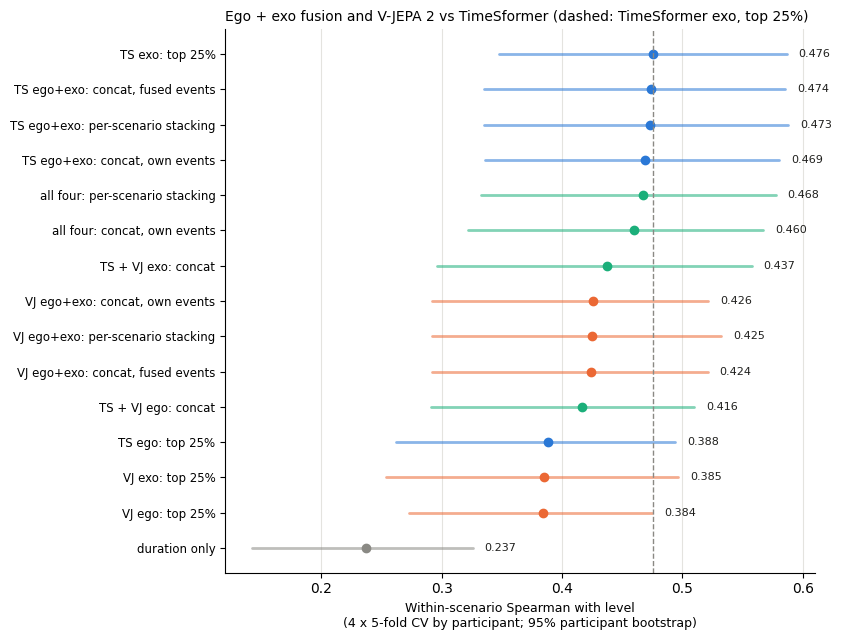

In [7]:
import matplotlib.pyplot as plt

COLORS = {"TS": "#2a78d6", "VJ": "#eb6834", "mix": "#1baf7a", "base": "#8a8984"}
def color_of(key):
    if key in ("scenario only", "duration only"):
        return COLORS["base"]
    if key.startswith(("all four", "TS + VJ")):
        return COLORS["mix"]
    return COLORS["VJ"] if key.startswith("VJ") else COLORS["TS"]
shown = ["duration only", *[k for k in [*REPS, *STACKS] if ("top 25%" in k and "L12" not in k) or "concat, own" in k
                            or "concat, fused" in k or "stacking" in k or k.startswith(("all four", "TS + VJ"))]]
shown = sorted(shown, key=lambda k: summary[k][0])
fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(shown) + 1.4))
for i, key in enumerate(shown):
    s = summary[key]
    ax.plot([s[1], s[2]], [i, i], color=color_of(key), lw=2, alpha=0.55, solid_capstyle="round")
    ax.plot(s[0], i, "o", color=color_of(key), ms=6)
    ax.text(s[2] + 0.01, i, f"{s[0]:.3f}", va="center", fontsize=8, color="#1f1f1d")
ax.axvline(summary["TS exo: top 25%"][0], color="#8a8984", ls="--", lw=1)
ax.set_yticks(range(len(shown)), shown, fontsize=8.5)
ax.set_xlabel("Within-scenario Spearman with level\n(4 x 5-fold CV by participant; 95% participant bootstrap)", fontsize=9)
ax.set_title("Ego + exo fusion and V-JEPA 2 vs TimeSformer (dashed: TimeSformer exo, top 25%)", fontsize=10, loc="left")
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fusion_vjepa.png", dpi=150, bbox_inches="tight")
plt.show()